# Walkthrough: FGP Illinois River basis panel (ACCY 512)

Each step shows one stage of the side project, from the raw USDA and USGS pulls to the regression results. Every code cell only **reads** files; nothing here changes the data. See `README.md` in this folder for the question and method, and `processing_log.md` for every decision.

## Setup

In [1]:
# Setup: find the repository root (the folder with CLAUDE.md), so the notebook works from any folder.
# Every cell below only READS files; nothing is written or changed.
from pathlib import Path
import sqlite3
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "CLAUDE.md").exists():
    ROOT = ROOT.parent
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)


def show(df, cols=None, n=5):
    """Print the table's shape, then its first n rows (key columns only)."""
    print(f"shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
    display(df[cols].head(n) if cols else df.head(n))

FGP = ROOT / "fgp_river_basis"

## Step 1: Raw USDA months and USGS river flow

The panel uses USDA report 3192 for Aug-Nov 2021 and 2022 (the Oct files are shared with the main project) and USGS daily mean flow of the Mississippi River at Memphis.

In [2]:
files = [(ROOT / "data/raw" if m == 10 else FGP / "data/raw") / f"3192_{y}-{m:02d}.csv"
         for y in [2021, 2022] for m in [8, 9, 10, 11]]
raw = pd.concat([pd.read_csv(f, low_memory=False) for f in files], ignore_index=True)
print("USDA 3192, 8 monthly files")
show(raw, ["report_date", "trade_loc", "delivery_point", "commodity", "current",
           "basis Min", "basis Max", "basis Min Futures Month"])

# USGS rdb file: tab-separated, '#' comment lines, then a format line to skip (same as fgp_03)
flow = pd.read_csv(FGP / "data/raw/usgs_07032000_flow_2021-08_2022-11.rdb", sep="\t", comment="#",
                   dtype=str).iloc[1:]
val = [c for c in flow.columns if c.endswith("_00060_00003")][0]
flow = pd.DataFrame({"date": flow["datetime"], "flow_cfs": pd.to_numeric(flow[val])})
print("\nUSGS 07032000, daily mean flow (cubic feet per second)")
show(flow)

USDA 3192, 8 monthly files
shape: 8,205 rows x 55 columns


,report_date,trade_loc,delivery_point,commodity,current,basis Min,basis Max,basis Min Futures Month
0,08/31/2021,North Illinois River,Barge Loading Elevators,Soybeans,No,-44.0,-19.0,November (X)
1,08/31/2021,North Illinois River,Barge Loading Elevators,Soybeans,Yes,-22.0,32.0,November (X)
2,08/31/2021,South Illinois River,Barge Loading Elevators,Soybeans,No,-25.0,-13.0,November (X)
3,08/31/2021,South Illinois River,Barge Loading Elevators,Soybeans,Yes,-25.0,5.0,November (X)
4,08/31/2021,Little Egypt,Country Elevators,Soybeans,No,-33.0,12.0,November (X)



USGS 07032000, daily mean flow (cubic feet per second)
shape: 487 rows x 2 columns


,date,flow_cfs
1,2021-08-01,390000
2,2021-08-02,380000
3,2021-08-03,381000
4,2021-08-04,385000
5,2021-08-05,390000


**What to notice:** the USDA files hold every grain, region and delivery period, and the flow file has one value per calendar day (487 days); the next step keeps only what the panel needs.

## Step 2: River basis panel

`fgp_03_build_panel.py` keeps corn bids for current delivery in 4 regions, on days when all four quote the December futures, and adds the River, Y2022 and Post dummies and the river flow.

In [3]:
panel = pd.read_csv(FGP / "data/river_basis_panel.csv")
show(panel)
print(pd.crosstab(panel["region"], pd.to_datetime(panel["date"]).dt.year).to_string())

shape: 448 rows x 9 columns


,date,region,basis_cents,futures_month,River,Y2022,Post,river_flow_cfs,flow_100k
0,2021-09-01,North Central,-1.0,December (Z),0,0,0,325000,3.25
1,2021-09-01,North Illinois River,-7.0,December (Z),1,0,0,325000,3.25
2,2021-09-01,South Central,13.0,December (Z),0,0,0,325000,3.25
3,2021-09-01,South Illinois River,2.5,December (Z),1,0,0,325000,3.25
4,2021-09-02,North Central,-1.0,December (Z),0,0,0,330000,3.30


date                  2021  2022
region                          
North Central           60    52
North Illinois River    60    52
South Central           60    52
South Illinois River    60    52


**What to notice:** the result is 448 rows = 112 trading days x 4 regions; basis is in cents/bu here, and 55 days were dropped where not all regions quoted December futures.

## Step 3: Basis chart

`fgp_04_chart.py` plots basis by region for 2021 and 2022 side by side, with a dotted line at Oct 1, where Post starts.

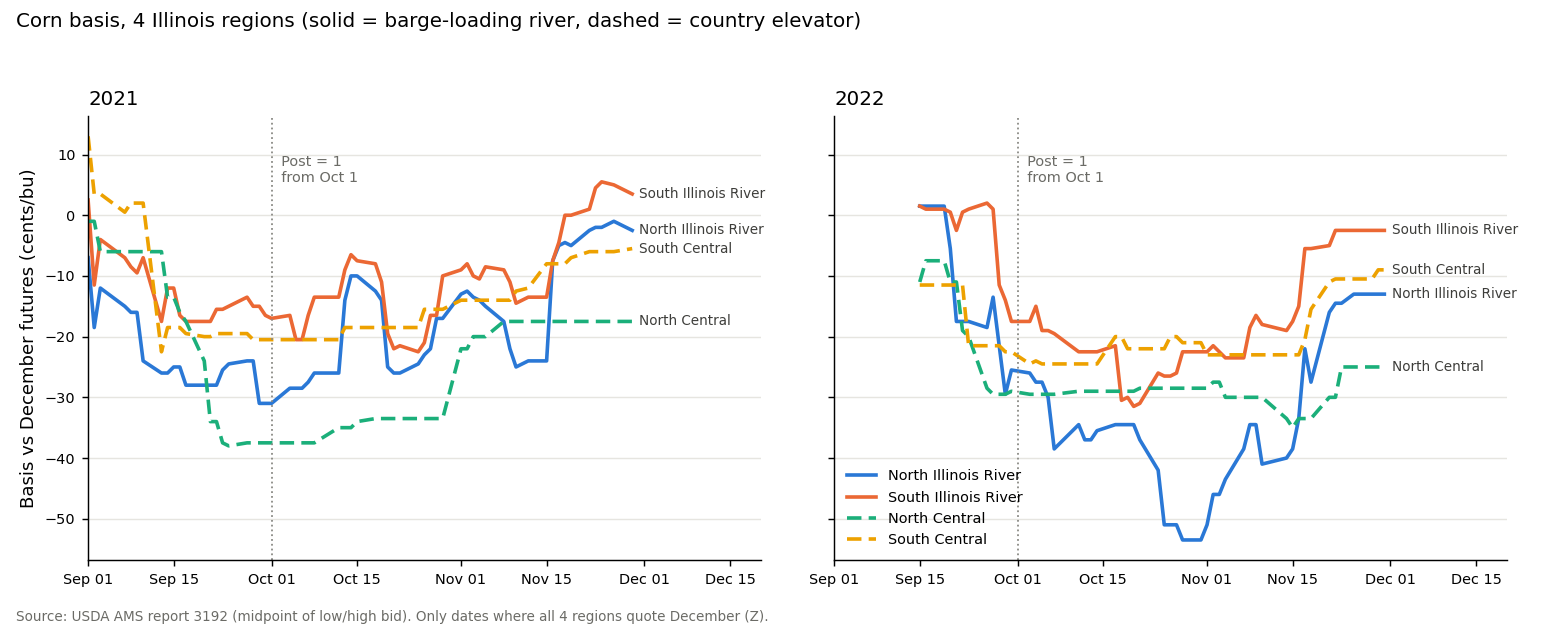

In [4]:
display(Image(filename=str(FGP / "outputs/fgp_basis_chart.png"), width=800))

**What to notice:** compare the river regions with the country regions after Oct 1 in 2022 versus 2021; the regression in the next step puts a number on that difference.

## Step 4: Regression results

The same models as `fgp_05_models.py`, refit here from the panel (nothing is saved). Model B (main) is the difference-in-differences; Model A (alternative) links river basis to flow.

In [5]:
import statsmodels.formula.api as smf

MODELS = {  # same formulas, key terms and standard errors as fgp_05_models.py
    "Model B (main)": ("basis_cents ~ River * Y2022 * Post", "River:Y2022:Post"),
    "Model A (alternative)": ("basis_cents ~ River + flow_100k + River:flow_100k", "River:flow_100k"),
}
df = pd.read_csv(FGP / "data/river_basis_panel.csv", parse_dates=["date"])
df = df.sort_values(["region", "date"]).reset_index(drop=True)
series_id = pd.factorize(df["region"] + "_" + df["date"].dt.year.astype(str))[0]  # 8 region-year series

rows = []
for name, (formula, key) in MODELS.items():
    model = smf.ols(formula, data=df)
    hc1 = model.fit(cov_type="HC1")
    nw = model.fit(cov_type="hac-panel", cov_kwds={"groups": series_id, "maxlags": 5})
    rows.append({"model": name, "key term": key, "coef (cents)": hc1.params[key],
                 "SE HC1": hc1.bse[key], "p HC1": hc1.pvalues[key],
                 "SE Newey-West": nw.bse[key], "p Newey-West": nw.pvalues[key],
                 "R-squared": hc1.rsquared, "n": int(hc1.nobs)})
show(pd.DataFrame(rows).round(3))

shape: 2 rows x 9 columns


,model,key term,coef (cents),SE HC1,p HC1,SE Newey-West,p Newey-West,R-squared,n
0,Model B (main),River:Y2022:Post,-20.035,4.181,0.000,8.369,0.017,0.218,448
1,Model A (alternative),River:flow_100k,1.575,0.880,0.074,1.872,0.400,0.166,448


**What to notice:** in Model B, river basis fell about 20 cents more after Oct 1 in 2022 than in 2021, relative to country elevators, and it stays significant with Newey-West errors (p about 0.017); Model A's flow term does not (p about 0.40).